In [6]:
from IPython.display import Image,display
import base64
import os
from dotenv import load_dotenv
from openai import OpenAI



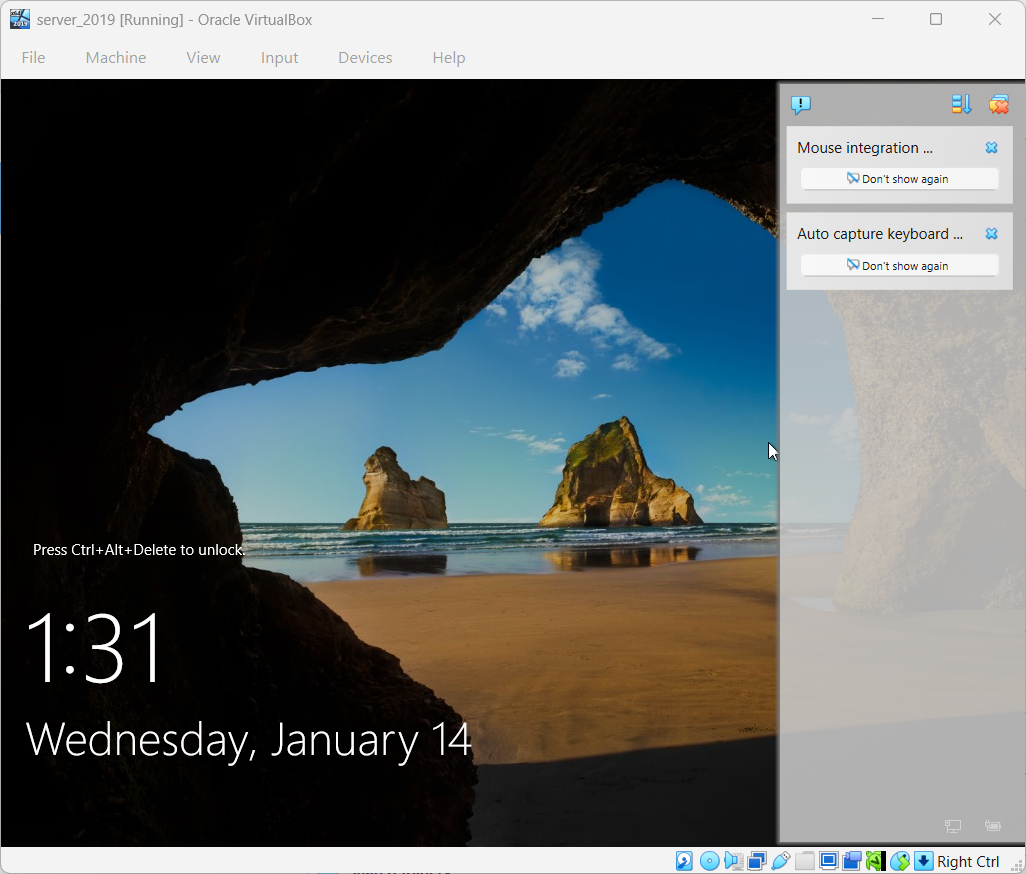

In [7]:
image_path = "virtual.png"
display(Image(image_path,width=800))

In [10]:

load_dotenv()
api_key = os.getenv("OPENAI_API_KEY")
client = OpenAI(api_key=api_key)

def encode_image(image_path):
    with open(image_path,'rb') as image_file:
        image_binary_data = image_file.read()
        return base64.b64encode(image_binary_data).decode("utf-8")

base64_image = encode_image(image_path)
system_message = "You are a tutor"
prompt = "what is time is it"

response = client.chat.completions.create(
    model='gpt-4o-mini',
    messages= [
        {'role':'system','content':system_message},
        {'role':'user','content':[
            {'type':'text','text':prompt},
            {'type':'image_url','image_url':
            {'url':f'data:image/jp;base64,{base64_image}'}}
        ]}
    ],
    temperature=0.0
    
)

In [11]:
print(response.choices[0].message.content)

The time displayed is 1:31, and the date is Wednesday, January 14.
